# Time-aware modelling — early risk of a long-running case

**Question:** *Can information available 14 days after a case starts predict whether it will become a long-running case?*

This notebook trains **one simple baseline (logistic regression)** and **one stronger comparison (random forest)** on the
leakage-safe 14-day features from `03_feature_engineering.ipynb`, and evaluates them **chronologically**.

"Long-running" means *a duration above the 75th percentile of the training period*. It is a relative label, **not** a legal delay,
lateness or a judgement of anyone's performance. This is a proof of concept for SPAR, not a production system.

### Workflow and test-set discipline

1. Fix a chronological split from case counts and follow-up only (no model results).
2. Learn **everything** from the training period: the label threshold, the activity vocabulary, preprocessing and the models.
3. Make every choice on the **validation** period: which logistic-regression variant, which final model, which probability threshold. The selection rules are written in code *before* any test result is computed.
4. **Freeze** the choices.
5. Score the **test** period once. Sensitivity checks are reported afterwards and change nothing.

# 1. Imports and paths

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pm4py
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

candidates = [Path.cwd(), *Path.cwd().parents]
project_root = next(
    (folder for folder in candidates
     if (folder / "notebooks" / "01_data_loading.ipynb").is_file()
     and (folder / "src").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Start Jupyter from inside the capstone project.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src import features as F
from src import models as M

features_path = project_root / "data" / "processed" / "case_features_14d.csv"
xes_path = project_root / "data" / "raw" / "BPIC15_1.xes"
figures_dir = project_root / "outputs" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)
for path in (features_path, xes_path):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {path.relative_to(project_root)} — run the earlier notebooks first.")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)
EXPECTED_ROWS = 917
FOLLOW_UP_DAYS = 365



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




# 2. Load the 14-day feature dataset

In [2]:
table = F.load_features_csv(features_path)
print("Shape:", table.shape)
assert len(table) == EXPECTED_ROWS, "unexpected number of prediction-eligible cases"
assert table["case_id"].is_unique, "duplicate case_id"
assert table["event_log_days"].notna().all(), "missing outcome duration"

forbidden = ["endDate", "requestComplete", "last_phase", "caseStatus", "variant", "dueDate", "planned", "dateFinished"]
predictor_candidates = F.predictor_columns(table)
assert not [c for c in predictor_candidates if any(f.lower() in c.lower() for f in forbidden)]
assert not set(predictor_candidates) & set(F.METADATA_COLUMNS)
print("One row per case, no missing outcome, no future-state fields among predictors.")
table = table.set_index("case_id")

Shape: (917, 47)
One row per case, no missing outcome, no future-state fields among predictors.


# 3. Raw snapshot events (for the train-only activity vocabulary)

The activity flags in the CSV were selected on all 917 cases. To keep the test period out of every choice, the activity vocabulary
is rebuilt from the raw 14-day snapshot events using **training cases only** (Section 7). The raw log also provides the end of the
extract (for follow-up) and `requestComplete` (for one sensitivity check only, never as a predictor).

In [3]:
df = pm4py.convert_to_dataframe(pm4py.read_xes(str(xes_path), return_legacy_log_object=True))
df[F.EVENT_ORDER] = np.arange(len(df))
timing = F.case_timing(df)
snap = F.snapshot_events(F.prepare_events(df), timing)
assert set(timing.index[timing["prediction_eligible"]]) == set(table.index), "CSV and raw snapshot disagree"
extract_end = df[F.TIMESTAMP].max()
request_complete = df.groupby(F.CASE)["case:requestComplete"].first().str.upper().eq("TRUE").reindex(table.index)
print("Snapshot events:", len(snap), "| extract ends:", extract_end)

C:\SPAR_CAPSTONE\.venv\Lib\site-packages\pm4py\utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


Snapshot events: 10930 | extract ends: 2015-07-31 22:00:00+00:00


# 4. Chronological split design

Boundaries are fixed from **case counts, follow-up and positive coverage by start year**, not from model performance.
The positive coverage below uses the P75 of the candidate training years (2010–2012), which is exactly the threshold used later.

In [4]:
start_local = table["case_start"].dt.tz_convert(F.LOCAL_TIMEZONE)
start_year = start_local.dt.year
candidate_threshold = table.loc[start_year <= 2012, "event_log_days"].quantile(M.LABEL_PERCENTILE)
follow_up = M.follow_up_flag(table["case_start"], extract_end, FOLLOW_UP_DAYS)
by_year = pd.DataFrame({
    "cases": start_year.value_counts().sort_index(),
    "first start": table.groupby(start_year)["case_start"].min().dt.date,
    "last start": table.groupby(start_year)["case_start"].max().dt.date,
    f"positives (> {candidate_threshold:.1f} d)": (table["event_log_days"] > candidate_threshold).groupby(start_year).sum(),
    "positive %": (table["event_log_days"] > candidate_threshold).groupby(start_year).mean().mul(100).round(1),
    f">= {FOLLOW_UP_DAYS} d follow-up": follow_up.groupby(start_year).sum(),
})
display(by_year)

,cases,first start,last start,positives (> 104.6 d),positive %,>= 365 d follow-up
case_start,,,,,,
2010,51,2010-10-05,2010-12-30,18,35.3,51
2011,287,2011-01-04,2011-12-30,68,23.7,287
2012,261,2012-01-01,2012-12-26,64,24.5,261
2013,175,2013-01-03,2013-12-27,51,29.1,175
2014,136,2014-01-05,2014-12-23,20,14.7,93
2015,7,2015-01-08,2015-01-14,0,0.0,0


**Chosen split (calendar years, local time):**

| Split | Start dates | Reason |
|---|---|---|
| **Train** | Oct 2010 – Dec 2012 | All the earliest cases. 2010 is partial (from October) and too small to stand alone, so it is merged into training. |
| **Validation** | Jan – Dec 2013 | The next complete year, with enough positives to compare models and choose a threshold. |
| **Test** | Jan 2014 – Jan 2015 | The latest cases, for the most realistic "future" evaluation. 2015 has only 7 eligible cases, so it is merged into test. |

Calendar-year boundaries are simple to explain and give roughly 65% / 19% / 16% of the cases.

**Censoring concern.** Cases started in 2014 had at most about 1.5 years to finish before the extract ended. Long cases from that
period are often still open, and open cases are not in the labelled cohort. The test period therefore contains **fewer long-running
cases** than earlier years (visible above), and its positives are a selected subset. Test results must be read with that in mind;
Section 13 checks the subset with at least one year of follow-up.

In [5]:
VALIDATION_START = pd.Timestamp("2013-01-01", tz=F.LOCAL_TIMEZONE)
TEST_START = pd.Timestamp("2014-01-01", tz=F.LOCAL_TIMEZONE)
split = M.chronological_split(table["case_start"], VALIDATION_START, TEST_START)
table["split"] = split
table[follow_up.name] = follow_up
print(split.value_counts().reindex([M.TRAIN, M.VALIDATION, M.TEST]).to_string())
for name in (M.TRAIN, M.VALIDATION, M.TEST):
    starts = table.loc[split == name, "case_start"].dt.tz_convert(F.LOCAL_TIMEZONE)
    print(f"{name:>10}: {starts.min().date()} .. {starts.max().date()}")

split
train         599
validation    175
test          143
     train: 2010-10-06 .. 2012-12-27
validation: 2013-01-04 .. 2013-12-28
      test: 2014-01-06 .. 2015-01-15


# 5. Follow-up robustness flag

`follow_up_365d` = the case started at least 365 days before the extract ended (start on or before 31 July 2014).
It is **not** used to exclude cases from the primary analysis; it defines a sensitivity subset (Section 13).

In [6]:
display(pd.crosstab(table["split"], table[follow_up.name]).reindex([M.TRAIN, M.VALIDATION, M.TEST]))

follow_up_365d,False,True
split,,
train,0,599
validation,0,175
test,50,93


# 6. Train-only label threshold

`train_p75_days` is the 75th percentile of `event_log_days` among **training** cases only. The **same number** labels every split;
it is never recomputed on validation or test.

In [7]:
train_p75_days = M.train_threshold(table["event_log_days"], split)
table["long_running"] = M.long_running_label(table["event_log_days"], train_p75_days)
print(f"train_p75_days = {train_p75_days:.2f} days  (exploratory full-cohort value was 102.53; not used)")
class_table = table.groupby("split")["long_running"].agg(cases="size", positives="sum")
class_table["negatives"] = class_table["cases"] - class_table["positives"]
class_table["positive rate %"] = (class_table["positives"] / class_table["cases"] * 100).round(1)
display(class_table.reindex([M.TRAIN, M.VALIDATION, M.TEST]))

train_p75_days = 104.56 days  (exploratory full-cohort value was 102.53; not used)


,cases,positives,negatives,positive rate %
split,,,,
train,599,150,449,25.0
validation,175,51,124,29.1
test,143,20,123,14.0


# 7. Train-only activity vocabulary

Same outcome-independent rule as notebook 03, but fitted on **training cases only**: activity codes present by day 14 in 10–90%
of *training* cases. The selected vocabulary is then applied unchanged to validation and test. `first_activity` and
`latest_activity_at_snapshot` are rebuilt **ungrouped**; rare values are grouped by the encoder, which is fitted on training data only.

In [8]:
train_ids = table.index[split == M.TRAIN]
activity_table, train_codes = F.train_vocabulary_activity_features(snap, train_ids)
global_codes = sorted(c.removeprefix(F.ACTIVITY_FLAG_PREFIX) for c in table.columns if c.startswith(F.ACTIVITY_FLAG_PREFIX))
print(f"Train-selected activity codes: {len(train_codes)}  (global CSV selection: {len(global_codes)})")
print("Only in train selection:", sorted(set(train_codes) - set(global_codes)))
print("Only in global selection:", sorted(set(global_codes) - set(train_codes)))

core = table[F.CORE_NUMERIC_FEATURES + ["split", "long_running", "event_log_days", "case_start", follow_up.name]]
model_table = core.join(activity_table, how="left")
assert model_table[activity_table.columns].notna().all().all()
print("Modelling table:", model_table.shape)

Train-selected activity codes: 16  (global CSV selection: 20)
Only in train selection: ['01_HOOFD_100']
Only in global selection: ['01_HOOFD_065_0', '01_HOOFD_090', '01_HOOFD_100_0', '01_HOOFD_110_0', '01_HOOFD_180']
Modelling table: (917, 42)


# 8. Feature sets

The **main feature set** = all day-14 predictors, minus columns that are constant **in the training period**
(they carry no information). Nothing is dropped for performing poorly. Metadata and outcome columns are never predictors.

In [9]:
train_rows = model_table[split == M.TRAIN]
binary_features = [F.ACTIVITY_FLAG_PREFIX + c for c in train_codes]
categorical_features = list(F.CATEGORICAL_FEATURES)
numeric_features = list(F.CORE_NUMERIC_FEATURES)
dropped_constant = M.constant_columns(train_rows[numeric_features + binary_features + categorical_features])
numeric_features = [c for c in numeric_features if c not in dropped_constant]
binary_features = [c for c in binary_features if c not in dropped_constant]
all_features = numeric_features + categorical_features + binary_features
print("Dropped (constant in training):", dropped_constant)
print(f"Numeric: {len(numeric_features)} | categorical: {len(categorical_features)} | binary activity flags: {len(binary_features)} "
      f"| total predictors: {len(all_features)}")
assert not set(all_features) & {"case_id", "case_start", "snapshot_time", "case_end", "event_log_days", "elapsed_days", "long_running", "split"}

X = {name: model_table.loc[split == name, all_features] for name in (M.TRAIN, M.VALIDATION, M.TEST)}
y = {name: model_table.loc[split == name, "long_running"] for name in (M.TRAIN, M.VALIDATION, M.TEST)}

Dropped (constant in training): ['activities_repeated_more_than_once_14d']
Numeric: 18 | categorical: 2 | binary activity flags: 16 | total predictors: 36


# 9. Model 1 — logistic regression baseline

Pipeline: numeric → `StandardScaler`; categorical → `OneHotEncoder(handle_unknown="ignore")` with categories seen in fewer than
20 training cases merged; activity flags → passed through. Everything is fitted on **training data only**. Fixed configuration: `C = 1.0`.

Two variants are compared on validation: standard and `class_weight="balanced"` (upweights the minority class).
**Pre-set rule:** the official baseline is the variant with the higher validation PR-AUC; if they are within 0.01, the one with the higher validation F1 at 0.50.

In [10]:
def score_table(models, X_eval, y_eval, threshold=M.DEFAULT_PROBABILITY_THRESHOLD):
    return pd.DataFrame({name: M.evaluate(y_eval, model.predict_proba(X_eval)[:, 1], threshold) for name, model in models.items()}).T


logistic_models = {
    "logistic (standard)": M.logistic_pipeline(numeric_features, categorical_features, binary_features).fit(X[M.TRAIN], y[M.TRAIN]),
    "logistic (balanced)": M.logistic_pipeline(numeric_features, categorical_features, binary_features,
                                               class_weight="balanced").fit(X[M.TRAIN], y[M.TRAIN]),
}
logistic_validation = score_table(logistic_models, X[M.VALIDATION], y[M.VALIDATION])
display(logistic_validation.round(3))

standard, balanced = logistic_validation.loc["logistic (standard)"], logistic_validation.loc["logistic (balanced)"]
if abs(standard["pr_auc"] - balanced["pr_auc"]) >= 0.01:
    official_logistic = logistic_validation["pr_auc"].astype(float).idxmax()
else:
    official_logistic = logistic_validation["f1"].astype(float).idxmax()
print("Official logistic baseline (chosen on validation):", official_logistic)

,cases,prevalence,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
logistic (standard),175.0,0.291,0.669,0.405,0.294,0.341,0.599,0.372,102.0,22.0,36.0,15.0
logistic (balanced),175.0,0.291,0.383,0.303,0.863,0.449,0.609,0.377,23.0,101.0,7.0,44.0


Official logistic baseline (chosen on validation): logistic (balanced)


# 10. Model 2 — random forest comparison

One small, fixed configuration (no search): 500 trees, minimum 5 cases per leaf, `max_features="sqrt"`,
`class_weight="balanced_subsample"`, fixed random seed. Trees need no scaling; the same one-hot encoding is used.

In [11]:
forest = M.random_forest_pipeline(numeric_features, categorical_features, binary_features).fit(X[M.TRAIN], y[M.TRAIN])
candidates = {official_logistic: logistic_models[official_logistic], "random forest": forest}
validation_scores = score_table(candidates, X[M.VALIDATION], y[M.VALIDATION])
display(validation_scores.round(3))

,cases,prevalence,accuracy,precision,recall,f1,roc_auc,pr_auc,tn,fp,fn,tp
logistic (balanced),175.0,0.291,0.383,0.303,0.863,0.449,0.609,0.377,23.0,101.0,7.0,44.0
random forest,175.0,0.291,0.669,0.410,0.314,0.356,0.572,0.439,101.0,23.0,35.0,16.0


# 11. Final model and probability threshold — chosen on validation

**Pre-set rules:**

- **Final model:** higher validation PR-AUC (average precision). PR-AUC is the main metric because positives are a minority and it does not depend on a threshold. If the two models are within 0.02, the logistic regression is preferred as simpler and easier to explain.
- **Probability threshold:** start at 0.50. Another threshold (grid 0.10–0.90) is adopted only if it improves **validation** F1 by at least 0.05; otherwise 0.50 is kept.

In [12]:
pr_auc = validation_scores["pr_auc"].astype(float)
if pr_auc["random forest"] - pr_auc[official_logistic] > 0.02:
    final_name = "random forest"
else:
    final_name = official_logistic
final_model = candidates[final_name]

validation_probability = final_model.predict_proba(X[M.VALIDATION])[:, 1]
final_threshold, threshold_table = M.choose_probability_threshold(y[M.VALIDATION], validation_probability)
display(threshold_table[["threshold", "precision", "recall", "f1"]].round(3).set_index("threshold").T)
print(f"Final model: {final_name}")
print(f"Probability threshold: {final_threshold:.2f}")

threshold,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90
precision,0.291,0.293,0.296,0.300,0.301,0.310,0.315,0.329,0.410,0.529,1.000,1.000,0.0,0.0,0.0,0.0,0.0
recall,1.000,1.000,0.980,0.941,0.843,0.784,0.686,0.451,0.314,0.176,0.098,0.020,0.0,0.0,0.0,0.0,0.0
f1,0.451,0.453,0.455,0.455,0.443,0.444,0.432,0.380,0.356,0.265,0.179,0.038,0.0,0.0,0.0,0.0,0.0


Final model: random forest
Probability threshold: 0.25


# 12. Frozen choices → one evaluation on the test period

In [13]:
frozen = pd.Series({
    "label threshold (train P75, days)": round(train_p75_days, 2),
    "activity vocabulary": f"{len(train_codes)} codes selected on training cases",
    "predictors": len(all_features),
    "official logistic variant": official_logistic,
    "final model": final_name,
    "probability threshold": final_threshold,
}, name="frozen before test")
display(frozen.to_frame())

test_probability = {name: model.predict_proba(X[M.TEST])[:, 1] for name, model in candidates.items()}
results = []
for name, model in candidates.items():
    for part in (M.VALIDATION, M.TEST):
        probability = model.predict_proba(X[part])[:, 1]
        results.append({"model": name, "split": part, **M.evaluate(y[part], probability, final_threshold)})
results = pd.DataFrame(results).set_index(["model", "split"])
print(f"All metrics at the frozen probability threshold {final_threshold:.2f}; prevalence = share of long-running cases.")
display(results.round(3))

,frozen before test
"label threshold (train P75, days)",104.56
activity vocabulary,16 codes selected on training cases
predictors,36
official logistic variant,logistic (balanced)
final model,random forest
probability threshold,0.25


All metrics at the frozen probability threshold 0.25; prevalence = share of long-running cases.


cases  prevalence  accuracy  precision  recall     f1  roc_auc  pr_auc  tn   fp  fn  tp
model               split                                                                                              
logistic (balanced) validation    175       0.291     0.320      0.300   1.000  0.462    0.609   0.377   5  119   0  51
                    test          143       0.140     0.168      0.144   1.000  0.252    0.528   0.155   4  119   0  20
random forest       validation    175       0.291     0.343      0.300   0.941  0.455    0.572   0.439  12  112   3  48
                    test          143       0.140     0.238      0.150   0.950  0.259    0.492   0.142  15  108   1  19

In [14]:
final_test_probability = test_probability[final_name]
intervals = {metric: M.bootstrap_interval(y[M.TEST], final_test_probability, metric, threshold=final_threshold)
             for metric in ["roc_auc", "pr_auc", "precision", "recall", "f1"]}
test_final = results.loc[(final_name, M.TEST)]
print(f"Final model on TEST ({int(test_final['cases'])} cases, {int(y[M.TEST].sum())} long-running) with 95% bootstrap intervals:")
display(pd.DataFrame({
    "value": [test_final[m] for m in intervals],
    "95% CI low": [v[0] for v in intervals.values()],
    "95% CI high": [v[1] for v in intervals.values()],
}, index=list(intervals)).round(3))

Final model on TEST (143 cases, 20 long-running) with 95% bootstrap intervals:


,value,95% CI low,95% CI high
roc_auc,0.492,0.363,0.621
pr_auc,0.142,0.090,0.254
precision,0.150,0.089,0.214
recall,0.950,0.840,1.000
f1,0.259,0.164,0.352


### Reading the test result

- **On the test period neither model ranks cases better than chance.** ROC-AUC is about 0.5 and PR-AUC is about equal to the prevalence (0.14). The 95% interval for the final model's ROC-AUC spans roughly 0.36–0.62, so a weak signal cannot be ruled out either, but none is demonstrated.
- On **validation** (2013) the signal was **weak but present**: ROC-AUC about 0.57–0.61, PR-AUC 0.38–0.44 against a prevalence of 0.29. It did not carry over to 2014.
- The high test **recall** (0.95) is not a success. At the frozen threshold of 0.25 the model flags almost every case, so precision (0.15) is no better than picking cases at random. Accuracy is low for the same reason.
- This is a legitimate **negative result** of an honest chronological evaluation. Section 13 checks whether it depends on censoring or on the workload feature, and Section 13.1 discusses why.

### 12.1 Figures

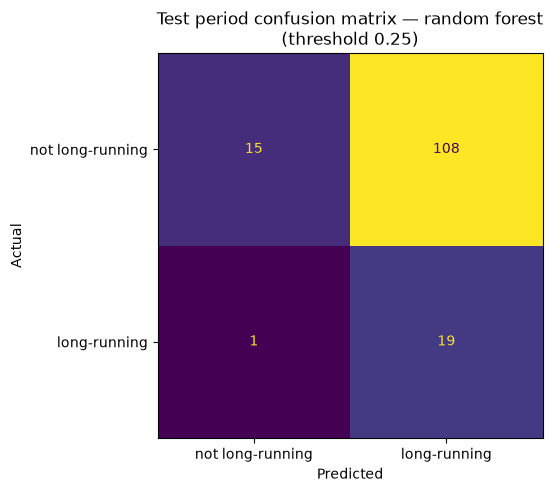

In [15]:
plt.figure(figsize=(5.5, 5))
ConfusionMatrixDisplay.from_predictions(
    y[M.TEST], (final_test_probability >= final_threshold).astype(int),
    display_labels=["not long-running", "long-running"], colorbar=False, ax=plt.gca())
plt.title(f"Test period confusion matrix — {final_name}\n(threshold {final_threshold:.2f})")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.savefig(figures_dir / "model_confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.show()

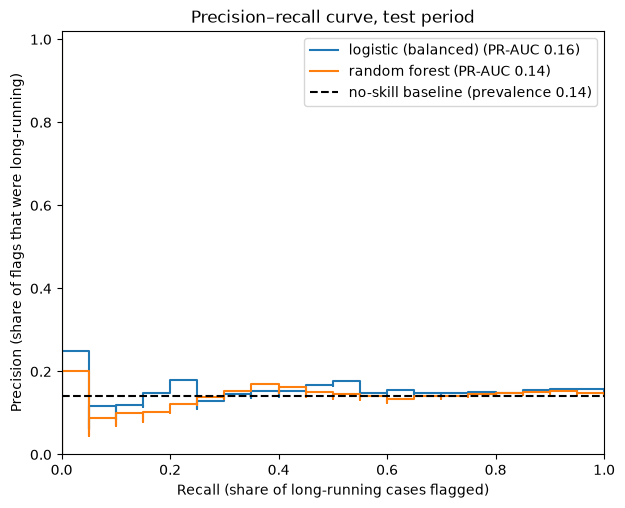

In [16]:
plt.figure(figsize=(7, 5.5))
for name, probability in test_probability.items():
    precision, recall, _ = precision_recall_curve(y[M.TEST], probability)
    average_precision = results.loc[(name, M.TEST), "pr_auc"]
    plt.step(recall, precision, where="post", label=f"{name} (PR-AUC {average_precision:.2f})")
plt.axhline(y[M.TEST].mean(), linestyle="--", color="black", label=f"no-skill baseline (prevalence {y[M.TEST].mean():.2f})")
plt.title("Precision–recall curve, test period")
plt.xlabel("Recall (share of long-running cases flagged)")
plt.ylabel("Precision (share of flags that were long-running)")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend()
plt.savefig(figures_dir / "model_pr_curve_test.png", dpi=150, bbox_inches="tight")
plt.show()

# 13. Robustness checks (after freezing — they change nothing)

- **A. Follow-up ≥ 365 days:** the frozen model scored only on test cases that started at least a year before the extract ended (less censoring).
- **B. Without `workload_cases_active_prev_30d`:** the final model type is refitted on training data without the workload feature, keeping the same threshold. This checks that results do not hinge on the one feature that uses other cases' activity.
- **C. Strict outcome cohort (context only):** the frozen model scored on test cases with `requestComplete = TRUE` (the 774-style cohort from 02b). `requestComplete` is used only to pick the subset, never as a predictor.

In [17]:
def evaluate_subset(model, part, mask, feature_list=None):
    rows = (split == part) & mask
    data = model_table.loc[rows, feature_list or all_features]
    return M.evaluate(model_table.loc[rows, "long_running"], model.predict_proba(data)[:, 1], final_threshold)


all_cases = pd.Series(True, index=model_table.index)
robustness = {
    ("primary", M.VALIDATION): evaluate_subset(final_model, M.VALIDATION, all_cases),
    ("primary", M.TEST): evaluate_subset(final_model, M.TEST, all_cases),
    ("A: follow-up >= 365 d", M.TEST): evaluate_subset(final_model, M.TEST, model_table[follow_up.name]),
}

without_workload = [c for c in numeric_features if c != "workload_cases_active_prev_30d"]
if final_name == "random forest":
    reduced_model = M.random_forest_pipeline(without_workload, categorical_features, binary_features)
else:
    reduced_model = M.logistic_pipeline(without_workload, categorical_features, binary_features,
                                        class_weight="balanced" if "balanced" in final_name else None)
reduced_model.fit(X[M.TRAIN][without_workload + categorical_features + binary_features], y[M.TRAIN])
reduced_features = without_workload + categorical_features + binary_features
for part in (M.VALIDATION, M.TEST):
    robustness[("B: without workload feature", part)] = evaluate_subset(reduced_model, part, all_cases, reduced_features)
for part in (M.VALIDATION, M.TEST):
    robustness[("C: requestComplete = TRUE subset", part)] = evaluate_subset(final_model, part, request_complete)
robustness = pd.DataFrame(robustness).T
display(robustness[["cases", "prevalence", "precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float).round(3))

cases  prevalence  precision  recall     f1  roc_auc  pr_auc
primary                          validation  175.0       0.291      0.300   0.941  0.455    0.572   0.439
                                 test        143.0       0.140      0.150   0.950  0.259    0.492   0.142
A: follow-up >= 365 d            test         93.0       0.183      0.198   0.941  0.327    0.468   0.182
B: without workload feature      validation  175.0       0.291      0.294   0.941  0.449    0.567   0.452
                                 test        143.0       0.140      0.146   0.950  0.253    0.514   0.153
C: requestComplete = TRUE subset validation  119.0       0.176      0.187   0.952  0.312    0.699   0.360
                                 test         99.0       0.121      0.126   0.917  0.222    0.381   0.100

**Robustness results.**

- **A.** Restricting the test set to cases with at least a year of follow-up raises the prevalence (0.18) but **not** the ranking quality (ROC-AUC about 0.47). Censoring alone does not explain the missing signal.
- **B.** Removing the workload feature changes almost nothing. The result does not hinge on it.
- **C.** In the `requestComplete = TRUE` subset the validation ROC-AUC is higher (about 0.70), but the test ROC-AUC is lower (about 0.38). Small subsets give unstable numbers in both directions.

### 13.1 Post-hoc observations

*Written after the test evaluation. They did **not** change any frozen choice; they are lessons for a next iteration.*

1. **The threshold rule picked a "flag almost everyone" threshold.** The pre-set rule (adopt a threshold if validation F1 improves by ≥ 0.05) chose 0.25. The validation table already shows that at 0.25 precision barely exceeds the prevalence. F1 rewards flagging everything when positives make up about 30% of cases (flag-all F1 = 2p / (1 + p) ≈ 0.45). A better rule would fix a minimum precision, or flag a fixed share of cases (e.g. the top 20% by risk). This does not affect the ranking metrics (ROC-AUC, PR-AUC), which show no test signal at any threshold.
2. **Why the validation signal did not transfer** (plausible, not proven):
    - **Few positives:** the test period has only 20 long-running cases, so metrics are very noisy.
    - **Selection by censoring:** the 2014 long-running cases are those that were long *and* closed before July 2015, a narrow band of durations.
    - **Drift:** the positive rate falls from 25–29% to 14%, and process practice may have changed.
    - **Weak features:** day-14 information is mostly the standard intake steps that almost every case goes through; the signal was weak even on validation.
3. **The validation ranking was mixed:** the random forest had the higher PR-AUC (the pre-set criterion), the balanced logistic regression the higher ROC-AUC. Neither was strong.

# 14. Interpretability — associations, not causes

Logistic-regression coefficients are on the **preprocessed scale**: a numeric coefficient is the change in log-odds per **one
standard deviation** (training scale); a flag/one-hot coefficient is the change when the activity/category is present.
A positive coefficient means **associated with higher predicted long-running risk**, holding the other features fixed. It does not
mean the feature *causes* long durations, and correlated features share and split their weight.

> **Caution:** these models showed only a weak signal on validation and none on test. The coefficients describe what the model
> learned from 2010–2012 training data; they are **not** reliable, general patterns.

In [18]:
coefficients = M.logistic_coefficients(logistic_models[official_logistic])
english_label = df.groupby(F.ACTIVITY)["activityNameEN"].agg(lambda s: s.value_counts().index[0])


def readable(name):
    name = name.split("__", 1)[1]
    if name.startswith(F.ACTIVITY_FLAG_PREFIX):
        code_ = name.removeprefix(F.ACTIVITY_FLAG_PREFIX)
        return f"occurred: {english_label.get(code_, code_)} ({code_})"
    for column, label in [("latest_activity_at_snapshot_", "latest step at day 14"), ("first_activity_", "first step")]:
        if name.startswith(column):
            code_ = name.removeprefix(column)
            if code_ == "infrequent_sklearn":
                return f"{label}: a rare step (< {M.MIN_CATEGORY_FREQUENCY} training cases)"
            return f"{label}: {english_label.get(code_, code_)} ({code_})"
    return name


coefficient_table = coefficients.rename(index=readable).sort_values()
print(f"{official_logistic}: strongest associations with LOWER predicted risk")
display(coefficient_table.head(8).round(3).to_frame())
print("Strongest associations with HIGHER predicted risk")
display(coefficient_table.tail(8)[::-1].round(3).to_frame())

importances = M.forest_importances(forest).rename(index=readable).sort_values(ascending=False)
print("Random forest: top 10 built-in (impurity) importances — magnitude only, no direction; biased towards continuous features")
display(importances.head(10).round(3).to_frame())

logistic (balanced): strongest associations with LOWER predicted risk


,coefficient
occurred: send procedure confirmation (01_HOOFD_065_1),-1.045
occurred: regular procedure without MER (04_BPT_005),-1.017
occurred: inform BAG administrator (01_HOOFD_050),-0.690
occurred: registrer date of publishing received request (01_HOOFD_100),-0.674
latest step at day 14: send confirmation receipt (01_HOOFD_030_1),-0.662
occurred: send confirmation receipt (01_HOOFD_020),-0.475
occurred: phase application received (01_HOOFD_015),-0.475
first step: register submission date request (01_HOOFD_010),-0.474


Strongest associations with HIGHER predicted risk


,coefficient
events_per_active_day,0.659
occurred: enter senddate acknowledgement (01_HOOFD_030_2),0.626
latest step at day 14: enter senddate acknowledgement (01_HOOFD_030_2),0.545
latest step at day 14: registration date publication (01_HOOFD_101),0.514
first step: a rare step (< 20 training cases),0.490
active_days_count_14d,0.450
days_since_last_event,0.404
occurred: OLO messaging active (01_HOOFD_011),0.381


Random forest: top 10 built-in (impurity) importances — magnitude only, no direction; biased towards continuous features


,importance
workload_cases_active_prev_30d,0.098
mean_inter_event_days,0.089
max_inter_event_days,0.083
days_since_last_event,0.079
median_inter_event_days,0.067
start_month,0.064
unique_activity_count_14d,0.054
event_count_14d,0.052
events_per_active_day,0.050
start_weekday,0.041


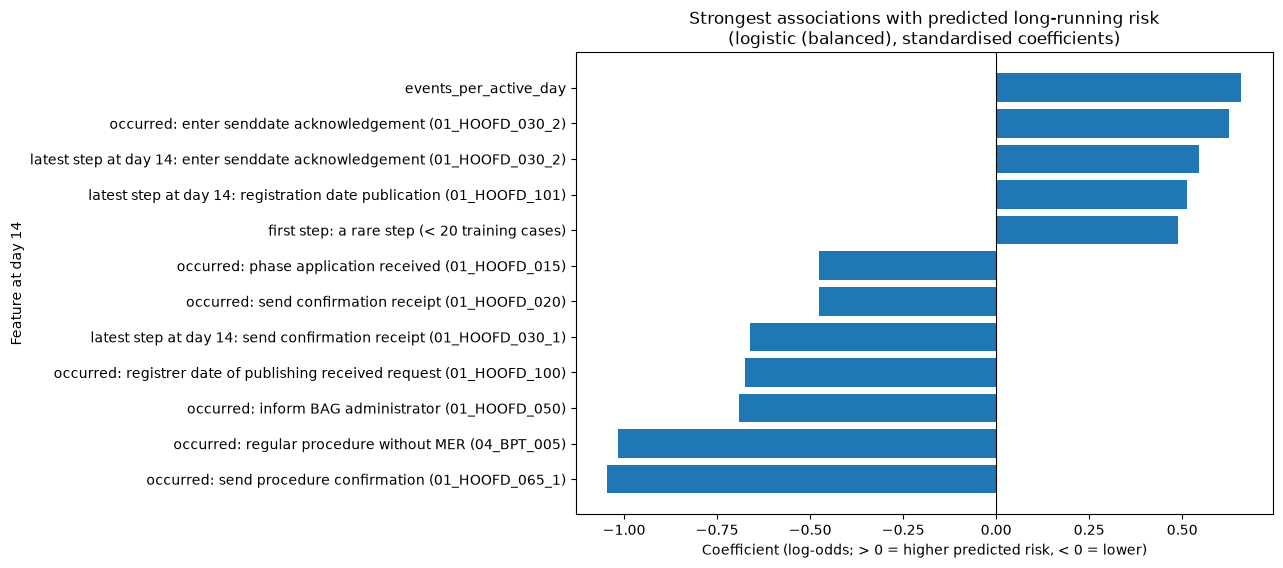

In [19]:
top = coefficient_table.reindex(coefficient_table.abs().sort_values(ascending=False).index[:12]).sort_values()
plt.figure(figsize=(9, 6))
plt.barh(top.index, top.to_numpy())
plt.axvline(0, color="black", linewidth=0.8)
plt.title(f"Strongest associations with predicted long-running risk\n({official_logistic}, standardised coefficients)")
plt.xlabel("Coefficient (log-odds; > 0 = higher predicted risk, < 0 = lower)")
plt.ylabel("Feature at day 14")
plt.savefig(figures_dir / "model_top_features.png", dpi=150, bbox_inches="tight")
plt.show()

# 15. Example of how SPAR could present an early risk signal

**Selection rule (no cherry-picking):** among the test cases that actually became long-running, take the one whose predicted
risk is the **median** for that group. That is a typical long-running case, whether or not the model flagged it.
This is an illustration, not an operational interface.

In [20]:
test_rows = model_table[split == M.TEST].assign(predicted_risk=final_test_probability)
positives = test_rows[test_rows["long_running"] == 1].sort_values("predicted_risk")
example_id = positives.index[len(positives) // 2]
example = test_rows.loc[example_id]
train_median = model_table.loc[split == M.TRAIN, numeric_features].median()
show = ["event_count_14d", "events_first_7_days", "days_since_last_event", "active_days_count_14d",
        "unique_resource_count_14d", "workload_cases_active_prev_30d"]
print(f"Case {example_id} — status at day 14 (snapshot {table.loc[example_id, 'snapshot_time'].date()})")
print(f"  Predicted long-running risk: {example['predicted_risk']:.0%}  "
      f"(flagged: {'yes' if example['predicted_risk'] >= final_threshold else 'no'}, threshold {final_threshold:.0%})")
print(f"  Actual outcome: {'long-running' if example['long_running'] else 'not long-running'} "
      f"({example['event_log_days']:.0f} days; threshold {train_p75_days:.0f} days)")
display(pd.DataFrame({"this case": example[show].astype(float), "typical training case (median)": train_median[show]}).round(1))
flags = [c for c in binary_features if example[c] == 1]
print("Early steps already done by day 14:", ", ".join(english_label[c.removeprefix(F.ACTIVITY_FLAG_PREFIX)] for c in flags) or "none")
print(f"Latest step at day 14: {english_label.get(example['latest_activity_at_snapshot'], example['latest_activity_at_snapshot'])}")

Case 9634805 — status at day 14 (snapshot 2014-03-12)
  Predicted long-running risk: 50%  (flagged: yes, threshold 25%)
  Actual outcome: long-running (188 days; threshold 105 days)


,this case,typical training case (median)
event_count_14d,18.0,11.0
events_first_7_days,18.0,8.0
days_since_last_event,9.0,7.5
active_days_count_14d,3.0,2.0
unique_resource_count_14d,1.0,1.0
workload_cases_active_prev_30d,65.0,81.0


Early steps already done by day 14: OLO messaging active, phase application received, send confirmation receipt, send confirmation receipt, enter senddate acknowledgement, registration date publication, forward to the competent authority, regular procedure without MER
Latest step at day 14: enter senddate acknowledgement


**Reading the example.** This is a typical long-running test case. At day 14 its risk score (about 50%) is above the frozen threshold,
so it would have been flagged, but so would most cases at that threshold. The case had *more* early activity than a typical training
case (18 events, all in the first week), then a pause of 9 days before the snapshot. A presentation could show exactly this kind of
card: the score, the threshold, and a few plain facts about the case at day 14. A person would then decide whether to look closer.
With the current model the score itself should **not** be trusted (no test signal).

# 16. What this proves for SPAR

What the experiment **supports**:

- An administrative **event history can be converted into point-in-time features** (what had happened by day 14) without using future information, and this was verified automatically.
- Early process information **can be tested for predictive signal** with an honest, chronological evaluation: train-only label threshold, train-only vocabulary and preprocessing, choices frozen on validation, one test evaluation.
- A **risk estimate can be produced before the case finishes**, and presented to a person as a prioritisation aid rather than a decision.
- **For this dataset, 14-day information did not give a reliable early signal.** There was a weak signal on 2013 validation and none on 2014 test. That is a useful finding: it shows what a SPAR pilot must check before relying on such scores, and it shows that the evaluation design catches over-optimism.

What it does **not** show:

- That early risk prediction **works**: the held-out result is at chance level.
- It is **not production-ready**: one municipality, ~900 cases, a single test year affected by censoring.
- It does **not detect legal delays** or deadline breaches; the label is relative to this municipality's own durations.
- It shows **associations, not causes**.
- It must **not make automatic decisions** about cases or people.
- It does **not generalise to Montenegro / SPAR** without retraining and validation on local data.

# 17. Limitations

- **Small test period:** the test year has few long-running cases, so its metrics have wide confidence intervals (Section 12).
- **Censoring:** recent cases that were still open are not in the labelled cohort, so the test period under-represents long cases.
- **Date-level timestamps:** same-day order follows the source file.
- **Relative label:** "long-running" = above the training P75; a different percentile would change the task.
- **Drift:** the process changed over 2010–2015; a model trained on 2010–2012 may age.
- **Threshold rule:** the pre-set F1-based rule chose a near "flag-all" threshold (Section 13.1). A precision-floor or top-k rule should be fixed in advance next time.

**Possible next steps (not done here):** a later snapshot (e.g. day 30) with more process information; richer, timing-verified
case attributes (e.g. `case:parts` if confirmed known at start); the other BPIC 2015 municipalities for more data; a top-k
alert rule chosen on validation.